In [9]:
import numpy as np
import random
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense

In [10]:
X_train = np.loadtxt('/home/pvg/Downloads/Dl3/DL2/input.csv', delimiter = ',')
Y_train = np.loadtxt('/home/pvg/Downloads/Dl3/DL2/labels.csv', delimiter = ',')

X_test = np.loadtxt('/home/pvg/Downloads/Dl3/DL2/input_test.csv', delimiter = ',')
Y_test = np.loadtxt('/home/pvg/Downloads/Dl3/DL2/labels_test.csv', delimiter = ',')

In [11]:
X_train = X_train.reshape(len(X_train), 100, 100, 3)
Y_train = Y_train.reshape(len(Y_train), 1)

X_test = X_test.reshape(len(X_test), 100, 100, 3)
Y_test = Y_test.reshape(len(Y_test), 1)

X_train = X_train/255.0
X_test = X_test/255.0

In [12]:
print("Shape of X_train: ", X_train.shape)
print("Shape of Y_train: ", Y_train.shape)
print("Shape of X_test: ", X_test.shape)
print("Shape of Y_test: ", Y_test.shape)

Shape of X_train:  (2000, 100, 100, 3)
Shape of Y_train:  (2000, 1)
Shape of X_test:  (400, 100, 100, 3)
Shape of Y_test:  (400, 1)


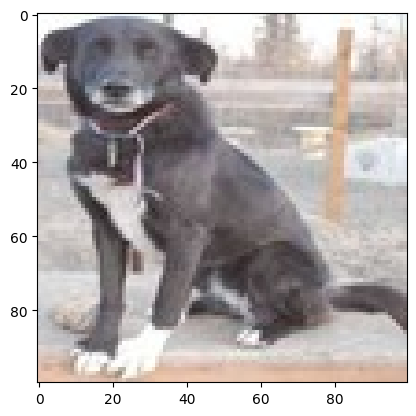

In [13]:
idx = random.randint(0, len(X_train))
plt.imshow(X_train[idx, :])
plt.show()

In [14]:
model = Sequential([
    Conv2D(32, (3,3), activation = 'relu', input_shape = (100, 100, 3)),
    MaxPooling2D((2,2)),
    
    Conv2D(32, (3,3), activation = 'relu'),
    MaxPooling2D((2,2)),
    
    Flatten(),
    Dense(64, activation = 'relu'),
    Dense(1, activation = 'sigmoid')
])


In [15]:
model = Sequential()

model.add(Conv2D(32, (3,3), activation = 'relu', input_shape = (100, 100, 3)))
model.add(MaxPooling2D((2,2)))

model.add(Conv2D(32, (3,3), activation = 'relu'))
model.add(MaxPooling2D((2,2)))

model.add(Flatten())
model.add(Dense(64, activation = 'relu'))
model.add(Dense(1, activation = 'sigmoid'))

In [16]:
model.compile(loss = 'binary_crossentropy', optimizer = 'adam', metrics = ['accuracy'])

In [17]:
model.fit(X_train, Y_train, epochs = 5, batch_size = 64)


Epoch 1/5


W0000 00:00:1791452325.364242   17392 cpu_allocator_impl.cc:82] Allocation of 240000000 exceeds 10% of free system memory.
W0000 00:00:1791452326.650288   17468 cpu_allocator_impl.cc:82] Allocation of 78675968 exceeds 10% of free system memory.


 1/32 ━━━━━━━━━━━━━━━━━━━━ 45s 1s/step - accuracy: 0.5312 - loss: 0.6911

W0000 00:00:1791452326.890534   17465 cpu_allocator_impl.cc:82] Allocation of 78675968 exceeds 10% of free system memory.
W0000 00:00:1791452327.033890   17467 cpu_allocator_impl.cc:82] Allocation of 78675968 exceeds 10% of free system memory.


 2/32 ━━━━━━━━━━━━━━━━━━━━ 9s 316ms/step - accuracy: 0.5078 - loss: 0.9466

W0000 00:00:1791452327.218545   17465 cpu_allocator_impl.cc:82] Allocation of 78675968 exceeds 10% of free system memory.


32/32 ━━━━━━━━━━━━━━━━━━━━ 11s 300ms/step - accuracy: 0.4955 - loss: 0.7503
Epoch 2/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 10s 302ms/step - accuracy: 0.5570 - loss: 0.6846
Epoch 3/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 10s 297ms/step - accuracy: 0.6405 - loss: 0.6360
Epoch 4/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 10s 296ms/step - accuracy: 0.7055 - loss: 0.5788
Epoch 5/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 10s 300ms/step - accuracy: 0.7340 - loss: 0.5345


In [18]:
model.evaluate(X_test, Y_test)


13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.6700 - loss: 0.5919


[0.5918875336647034, 0.6700000166893005]

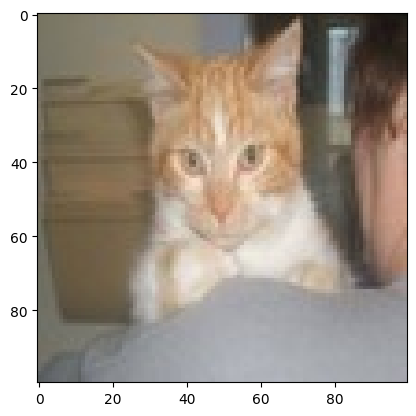

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
Our model says it is a : cat


In [19]:
idx2 = random.randint(0, len(Y_test))
plt.imshow(X_test[idx2, :])
plt.show()

y_pred = model.predict(X_test[idx2, :].reshape(1, 100, 100, 3))
y_pred = y_pred > 0.5

if(y_pred == 0):
    pred = 'dog'
else:
    pred = 'cat'
    
print("Our model says it is a :", pred)